<a href="https://colab.research.google.com/github/AzizArfaoui1/TP-ML-avanc-/blob/main/Test_Prioritize.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Business Understanding

In [35]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Conducting research on testcase prioritization especially in initial stages of software test cycle in companies

This data was gathered in [Jan, 2021], from a local industry's MIS, developed by a software team worked on company's whole software package including their management system.
The dataset is in .csv format, there are 1314 rows and 8 columns in this data set. The detail of these eight attributes are as under:

**B_Req**
Business Requirement


**R_Priority**
Requirement Priority of particular business requirement


**Weights**
Assigned weightage against "R_Priority(Requirement Priority)


**FP**
Function point of each testing task, which in our case are test cases against each requirement under covers a particular FP


**Complexity**
Complexity of a particular function point or related modules


**Time**
Estimated max time assigned to each Function Point of particular testing task


**Cost**
Calculated cost for each function point using complexity and time with function point estimation technique to calculate cost


**Priority**
assigned testcases Priority against each Function Point by the testing team.

The dataset can be used to analyze and apply classification or any machine learning algorithm to prioritize testcases.

In [36]:
# Setting up the environment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             accuracy_score,
                             ConfusionMatrixDisplay)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

# Data comprehension and cleaning

In [60]:
# Load the dataset
chemin = "/content/drive/MyDrive/Colab Notebooks/Test_Project_MIS.csv"
df = pd.read_csv(chemin)

In [61]:
# Display first 5 rows
print("First 5 rows:")
df.head()

First 5 rows:


,B_Req,R_Priority,Weights,FP,Complexity,Time,Cost,Priority
0,"1,C,3,""T-mis-2708,T-mis- 2151,T-mis- 560,T-mis...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,C,3.0,T-mis-1755,3.0,4.0,84.0,High
2,3,W,3.0,T-mis-3227,3.0,1.5,31.5,Medium
3,"4,S,2,""T-mis-2440,T-mis- 2659,T-mis- 1510"",1,4...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"5,C,3,""T-mis-2912,T-mis- 2042,T-mis- 1020"",5,4...",NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
# pint the shape of data
print(df.shape)

(1313, 8)


In [63]:
# Dataset information
print("\nDataset info:")
df.info()


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1313 entries, 0 to 1312
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   B_Req       1313 non-null   object 
 1   R_Priority  328 non-null    object 
 2   Weights     328 non-null    float64
 3   FP          328 non-null    object 
 4   Complexity  328 non-null    float64
 5   Time        328 non-null    float64
 6   Cost        328 non-null    float64
 7   Priority    328 non-null    object 
dtypes: float64(4), object(4)
memory usage: 82.2+ KB


In [64]:
# check for nan values
df.isna().values.any()

np.True_

In [65]:
# drop nan values
df = df.dropna()

In [66]:
df.shape

(328, 8)

In [ ]:
...

In [67]:
# check for duplicates
print(df.duplicated().sum())


0


In [68]:
# Clean the FP feature
df_fp = df['FP'].str.split(',', expand=True).stack().reset_index(level=1, drop=True).to_frame('FP')
df = df.drop('FP', axis=1).join(df_fp)
df['FP'] = df['FP'].str.strip()

# Convert data types
df['Weights'] = pd.to_numeric(df['Weights'], errors='coerce')
df['Complexity'] = pd.to_numeric(df['Complexity'], errors='coerce')
df['Time'] = pd.to_numeric(df['Time'], errors='coerce')
df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')

# Create new features
df['FP_Count'] = df.groupby('B_Req')['FP'].transform('count')
df['Cost_Per_Time'] = df['Cost'] / df['Time']

# Export cleaned data
df.to_csv('Cleaned_Project_MIS.csv', index=False)

In [69]:
# import "Cleaned_Project_MIS.csv":
df_new= pd.read_csv("/content/Cleaned_Project_MIS.csv")
df_new.head(5)


,B_Req,R_Priority,Weights,Complexity,Time,Cost,Priority,FP,FP_Count,Cost_Per_Time
0,2,C,3.0,3.0,4.0,84.0,High,T-mis-1755,1,21.0
1,3,W,3.0,3.0,1.5,31.5,Medium,T-mis-3227,1,21.0
2,6,S,2.0,3.0,4.0,84.0,Medium,T-mis-1533,1,21.0
3,14,S,2.0,3.0,1.5,31.5,Medium,T-mis-2279,1,21.0
4,15,S,2.0,3.0,1.0,21.0,Medium,T-mis-49,1,21.0


In [70]:
# Drop the FP_Count containing a unique value equal to 1
df_new = df_new.drop(columns=['FP_Count'])

In [71]:
# Handle categorical features
# Encode target variable
le_priority = LabelEncoder()
df_new['Priority'] = le_priority.fit_transform(df_new['Priority'])

le_rpriority = LabelEncoder()
df_new['R_Priority'] = le_rpriority.fit_transform(df_new['R_Priority'])

# Convert 'B_Req' to string and extract only relevant IDs (keeping numbers)
df_new["B_Req"] = df_new["B_Req"].astype(str).str.extract(r'(\d+)')
# Convert to numeric, coercing errors to NaN
df_new["B_Req"] = pd.to_numeric(df_new["B_Req"], errors='coerce')

In [72]:
# Calculate the frequency of each FP value, Replace each FP value with its frequency in the dataset. This can be useful
fp_freq = df_new['FP'].value_counts(normalize=True)

# Map the frequencies to the FP column
df_new['FP_freq'] = df_new['FP'].map(fp_freq)

# Drop the original FP column
df_new = df_new.drop('FP', axis=1)

In [50]:
# Checking the features type
print(df_new.dtypes)

B_Req              int64
R_Priority         int64
Weights          float64
Complexity       float64
Time             float64
Cost             float64
Priority           int64
Cost_Per_Time    float64
FP_freq          float64
dtype: object


# Modeling

## 1.Model1 : Decison Tree

In [ ]:
...

In [73]:
# splitting the data
X = df_new.drop(columns=['Priority'])
y = df_new['Priority']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [74]:
add = DecisionTreeClassifier(random_state=42)

add.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [75]:
# Predictions
y_pred = add.predict(X_test)

# Evaluation

Model Evaluation:
Accuracy: 0.61

Classification Report:
              precision    recall  f1-score   support

           C       0.15      0.29      0.20         7
           M       0.79      0.79      0.79        29
           S       0.62      0.50      0.56        30
           W       0.00      0.00      0.00         0

    accuracy                           0.61        66
   macro avg       0.39      0.39      0.39        66
weighted avg       0.65      0.61      0.62        66



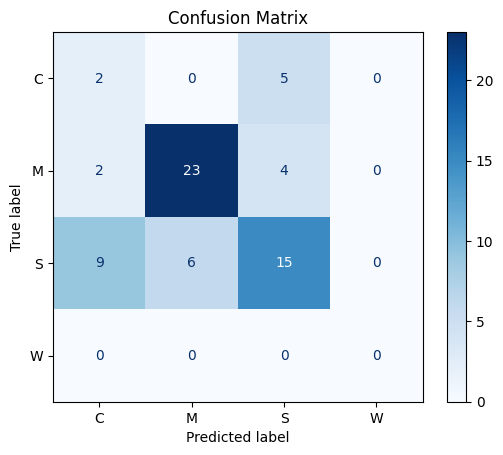

In [77]:
# Evaluation metrics
print("Model Evaluation:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=range(len(le.classes_)),   # force les 4 classes
    target_names=le.classes_,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=range(len(le.classes_)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# Plot he tree

In [78]:
feature_name= ['B_Req', 'R_Priority', 'Weights', 'Complexity', 'Time', 'Cost','Cost_Per_Time', 'FP_freq']
classes=["0","1","2"]

In [79]:
le.classes_

array(['C', 'M', 'S', 'W'], dtype=object)

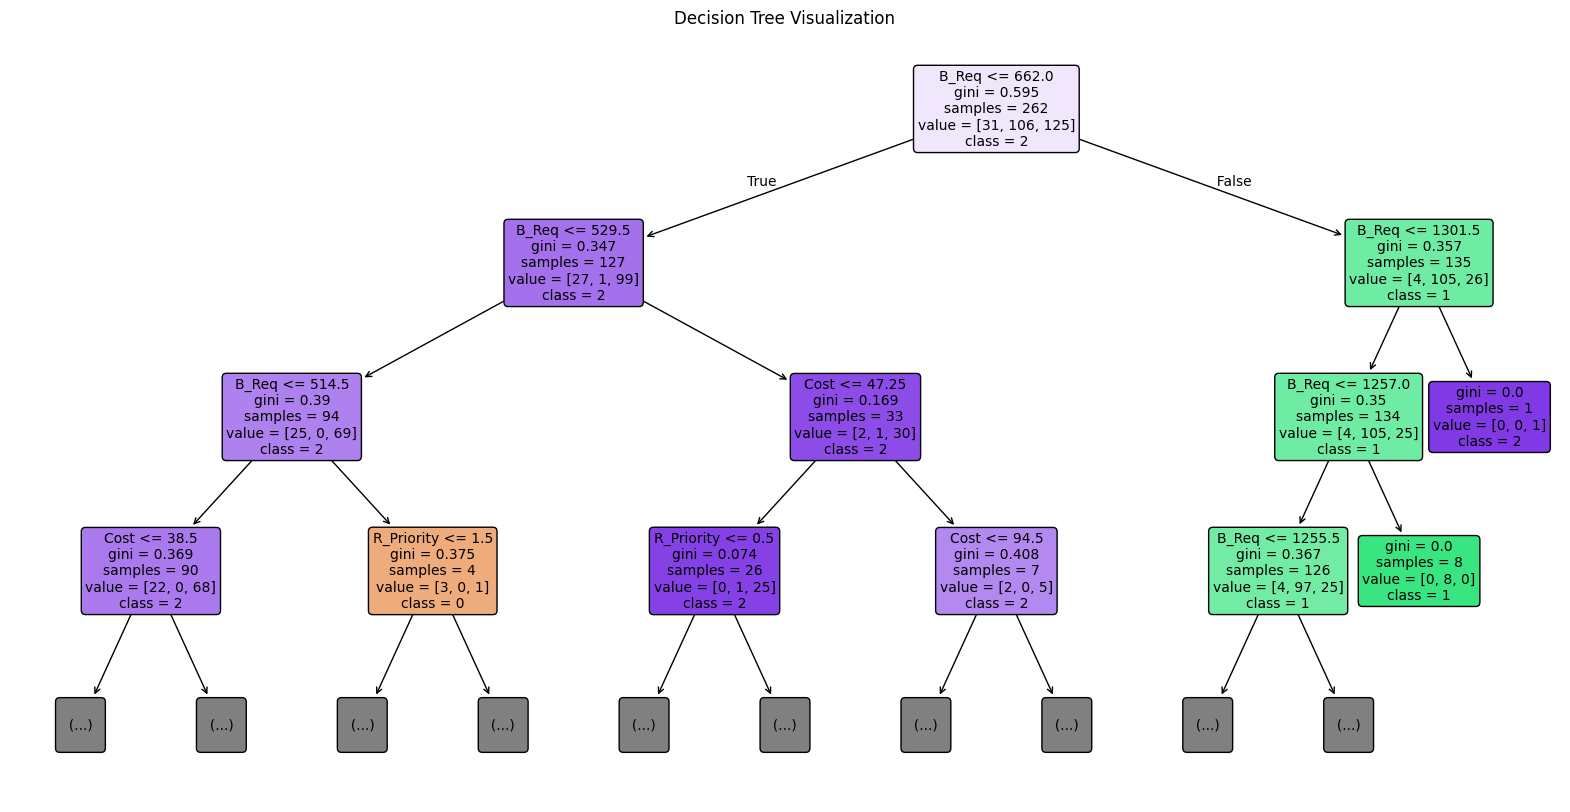

In [80]:
# ## 8. Visualize Decision Tree

plt.figure(figsize=(20, 10))
plot_tree(
    add,
    max_depth=3,
    feature_names=feature_name,
    class_names=classes,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Visualization')
plt.show()

In [81]:
# Assuming 'clf' is your trained decision tree model
tree_rules = export_text(add, feature_names=list(X.columns))

print(tree_rules)  # Display the rules

|--- B_Req <= 662.00
|   |--- B_Req <= 529.50
|   |   |--- B_Req <= 514.50
|   |   |   |--- Cost <= 38.50
|   |   |   |   |--- Time <= 1.75
|   |   |   |   |   |--- Cost <= 8.75
|   |   |   |   |   |   |--- B_Req <= 127.00
|   |   |   |   |   |   |   |--- B_Req <= 67.50
|   |   |   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |   |   |--- B_Req >  67.50
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- B_Req >  127.00
|   |   |   |   |   |   |   |--- R_Priority <= 1.50
|   |   |   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |   |   |--- R_Priority >  1.50
|   |   |   |   |   |   |   |   |--- B_Req <= 347.50
|   |   |   |   |   |   |   |   |   |--- B_Req <= 331.50
|   |   |   |   |   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |   |   |   |   |--- B_Req >  331.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- B_Req >  347.50
|   |   |   |   |   |   |   |   |   |--- class: 2
|   |   |   |   

# Print the feature importance

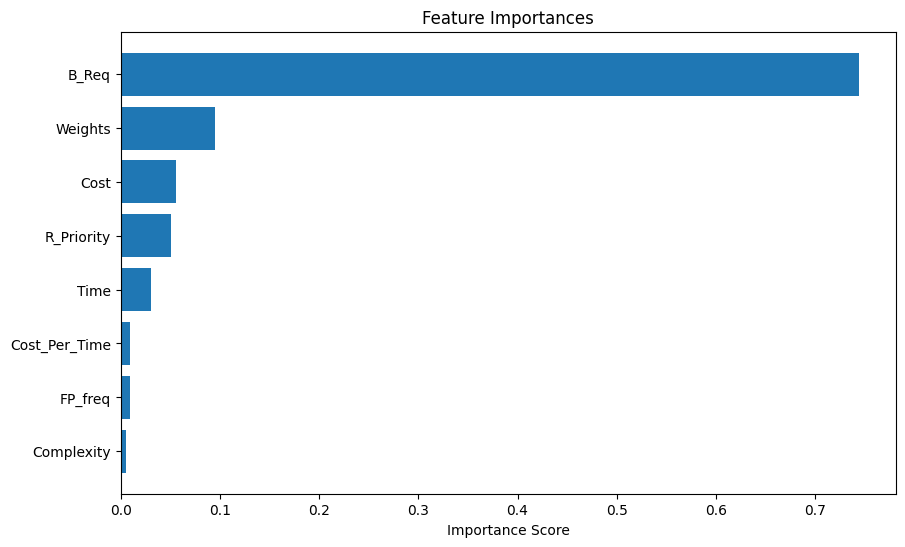

In [82]:
# ## 7. Feature Importance Analysis

# Extract feature importances
importances = add.feature_importances_

# Create DataFrame for visualization
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'])
plt.title('Feature Importances')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()

## 2. Model2 Random Forest

In [83]:
# Apply the random forest model and evalute the model
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [84]:
y_pred_rf = rf.predict(X_test)

In [85]:
from sklearn.metrics import accuracy_score, classification_report

print("Random Forest Evaluation:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf,
    labels=range(len(le_priority.classes_)),
    target_names=le_priority.classes_,
    zero_division=0
))

Random Forest Evaluation:
Accuracy: 0.64

Classification Report:
              precision    recall  f1-score   support

        High       0.14      0.14      0.14         7
         Low       0.79      0.79      0.79        29
      Medium       0.60      0.60      0.60        30

    accuracy                           0.64        66
   macro avg       0.51      0.51      0.51        66
weighted avg       0.64      0.64      0.64        66



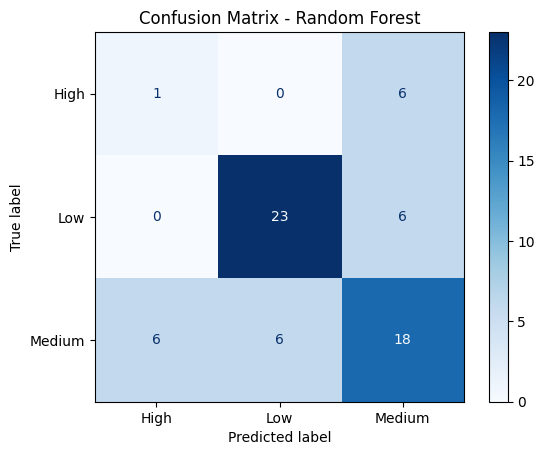

In [86]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf, labels=range(len(le_priority.classes_)))
ConfusionMatrixDisplay(cm, display_labels=le_priority.classes_).plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

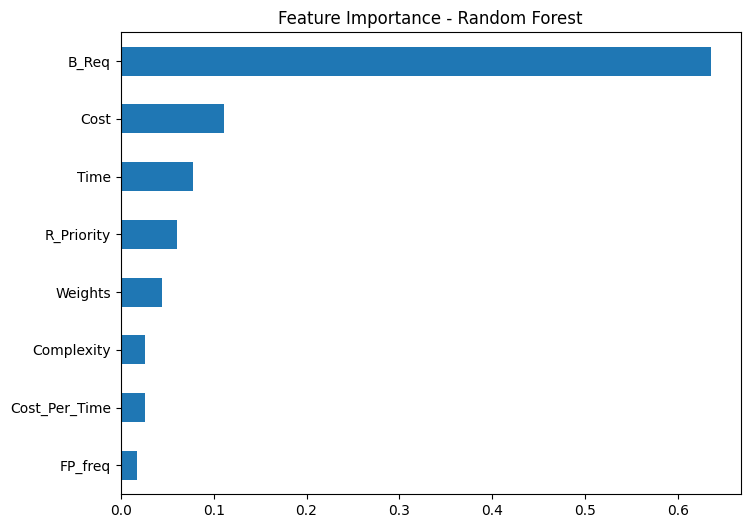

In [87]:
import pandas as pd

importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 6), title='Feature Importance - Random Forest')
plt.show()
